# Chapitre 1 - Cours 4 : fiabilité et tolérance aux fautes

Un système fiable continue de fonctionner correctement **même quand quelque chose se
passe mal**. Ce notebook précise ce qui peut mal se passer (matériel, logiciel, humains)
et quantifie les parades : redondance, indépendance des pannes, injection de fautes,
déploiements progressifs. Il couvre la section *Reliability* (*Hardware Faults*, *Software Errors*, *Human Errors*, *How Important Is Reliability?*).

**Plan.**

1. Fautes, défaillances et points de défaillance uniques.
2. Tolérer une faute, et le vérifier en injectant des fautes.
3. Les pannes matérielles : des événements rares qui deviennent quotidiens.
4. Redondance et pannes corrélées.
5. Les fautes logicielles, corrélées par nature.
6. Les erreurs humaines et les déploiements progressifs.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Fautes, défaillances et points de défaillance uniques (section *Reliability*)

Pour un logiciel, « fonctionner correctement » recouvre plusieurs attentes : rendre le
service attendu, tolérer les erreurs et les usages imprévus des utilisateurs, offrir des
performances suffisantes sous la charge prévue, empêcher les accès non autorisés. Être
fiable, c'est continuer à le faire **quand les choses tournent mal**. Le livre distingue
deux niveaux :

- une **faute** (fault) : un composant cesse de fonctionner correctement (un disque, une
  machine, un service externe) ;
- une **défaillance** (failure) : le système **dans son ensemble** cesse de rendre le
  service attendu.

C'est le même phénomène vu à deux échelles : la panne d'un disque est une défaillance
du disque, mais seulement une faute pour un système qui garde une copie des données
ailleurs. Un système est **tolérant aux fautes** s'il continue à rendre le service
malgré certaines fautes ; un composant dont la faute entraîne la défaillance de tout le
système est un **point de défaillance unique** (SPOF, single point of failure).

**Quantifier.** Si les composants tombent en panne indépendamment, la disponibilité
d'une chaîne de composants **tous nécessaires** est le produit de leurs disponibilités ;
celle de composants **redondants** (un seul suffit) vaut $1 - \prod (1 - a_i)$.
Comparons trois architectures d'une application web.

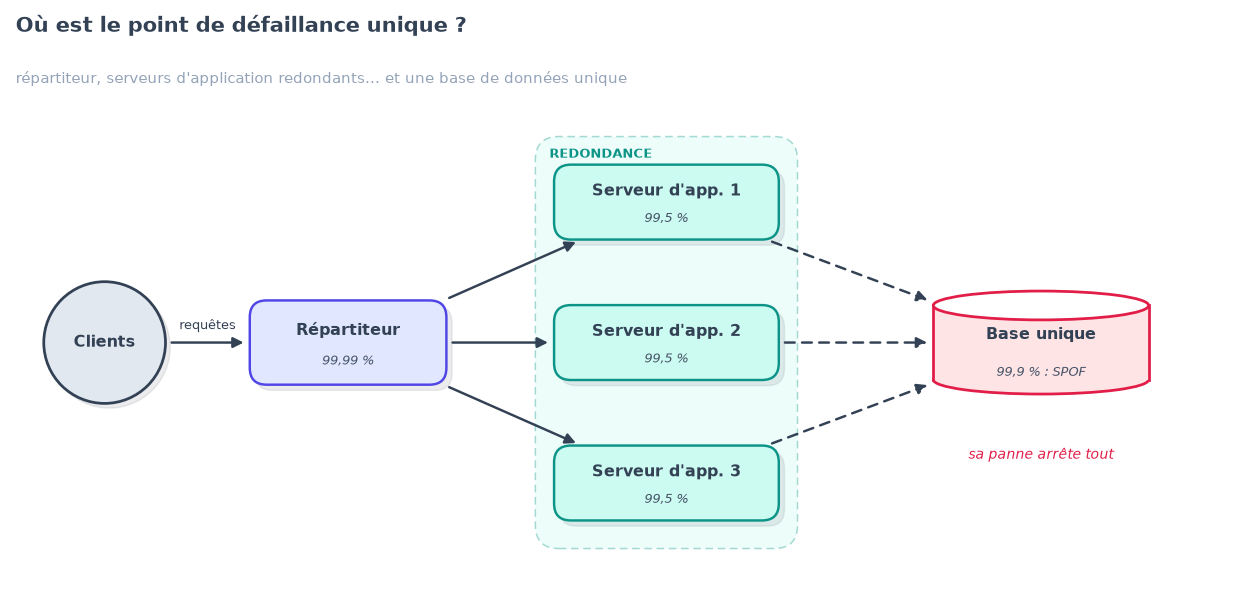

In [2]:
d = Diagram(13, 5.2, title="Où est le point de défaillance unique ?",
            subtitle="répartiteur, serveurs d'application redondants... et une base de données unique")
d.box("u", 1.0, 2.6, "Clients", kind="user", w=1.3, color=SLATE)
d.box("lb", 3.6, 2.6, "Répartiteur", sub="99,99 %", color=INDIGO, w=2.1)
d.box("db", 11.0, 2.6, "Base unique", sub="99,9 % : SPOF", color=ROSE, kind="db", w=2.3, h=1.1)
for i, y in enumerate([4.1, 2.6, 1.1]):
    d.box(f"a{i}", 7.0, y, f"Serveur d'app. {i + 1}", sub="99,5 %", color=TEAL, w=2.4, h=0.8)
    d.arrow("lb", f"a{i}")
    d.arrow(f"a{i}", "db", style="dashed")
d.arrow("u", "lb", "requêtes")
d.group(5.6, 0.4, 8.4, 4.8, "redondance", color=TEAL)
d.note(11.0, 1.4, "sa panne arrête tout", color=ROSE)
d.show()

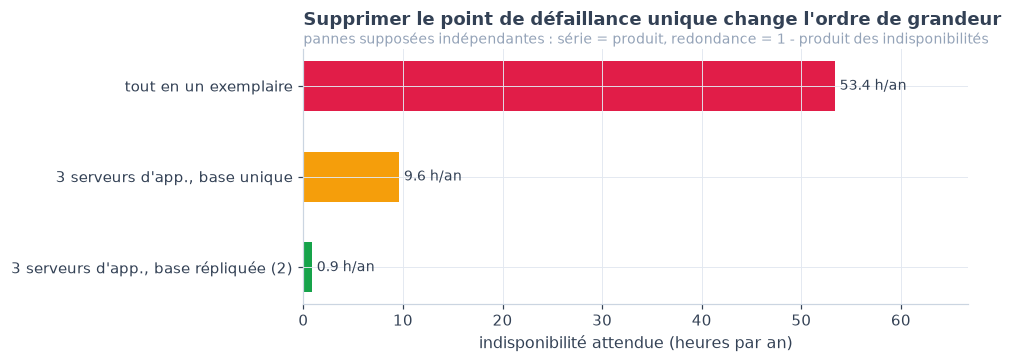

,disponibilité,neuf,indisponibilité par an (h)
tout en un exemplaire,0.9939,2.2151,53.3869
"3 serveurs d'app., base unique",0.9989,2.9586,9.6362
"3 serveurs d'app., base répliquée (2)",0.9999,3.9951,0.8859


In [3]:
a_lb, a_app, a_db = 0.9999, 0.995, 0.999
archis = {
    "tout en un exemplaire": rq.series_availability(a_lb, a_app, a_db),
    "3 serveurs d'app., base unique": rq.series_availability(a_lb, rq.parallel_availability(a_app, a_app, a_app), a_db),
    "3 serveurs d'app., base répliquée (2)": rq.series_availability(a_lb, rq.parallel_availability(a_app, a_app, a_app),
                                                                    rq.parallel_availability(a_db, a_db)),
}
A = pd.DataFrame({"disponibilité": archis}).assign(
    neuf=lambda df: df["disponibilité"].map(rq.nines),
    **{"indisponibilité par an (h)": lambda df: df["disponibilité"].map(lambda a: rq.downtime_minutes(a) / 60)})
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(A.index[::-1], A["indisponibilité par an (h)"].values[::-1], color=[GREEN, AMBER, ROSE], height=0.55)
annotate_bars(ax, "{:.1f} h/an")
ax.set_xlabel("indisponibilité attendue (heures par an)")
ax.set_xlim(0, A["indisponibilité par an (h)"].max() * 1.25)
ax.set_title("Supprimer le point de défaillance unique change l'ordre de grandeur")
subtitle(ax, "pannes supposées indépendantes : série = produit, redondance = 1 - produit des indisponibilités")
plt.tight_layout(); plt.show()
A

Tripler les serveurs d'application ne suffit pas : la base unique (8,8 h de panne par
an) domine. En la répliquant, l'indisponibilité tombe à moins d'une heure par an... à
condition que les pannes soient **indépendantes**, hypothèse qui sera mise à mal en
sections 4 et 5. La tolérance aux fautes est d'ailleurs toujours **limitée** à un certain
nombre de certains types de fautes : un système qui fonctionne tant qu'au moins $k$ de
ses $n$ répliques sont en vie (un quorum, chapitre 5) a pour
disponibilité $\sum_{i \ge k} \binom{n}{i} a^i (1-a)^{n-i}$.

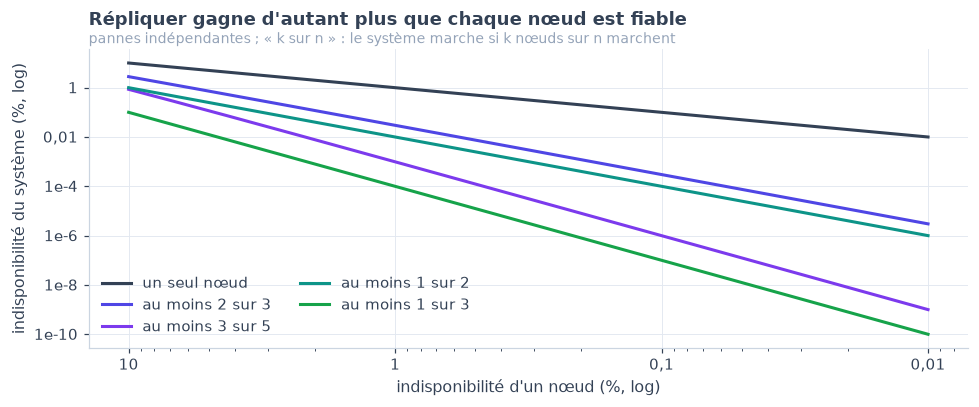

In [4]:
a_ = np.linspace(0.9, 0.9999, 300)
fig, ax = plt.subplots(figsize=(9, 3.8))
for (k, n), c in zip([(1, 1), (2, 3), (3, 5), (1, 2), (1, 3)], [SLATE, INDIGO, VIOLET, TEAL, GREEN]):
    ax.plot((1 - a_) * 100, [(1 - rq.k_of_n_availability(x, k, n)) * 100 for x in a_], color=c,
            label=f"au moins {k} sur {n}" if n > 1 else "un seul nœud")
ax.set_xscale("log"); ax.set_yscale("log"); rq.plain_log_axis(ax)
ax.invert_xaxis()
ax.set_xlabel("indisponibilité d'un nœud (%, log)"); ax.set_ylabel("indisponibilité du système (%, log)")
ax.set_title("Répliquer gagne d'autant plus que chaque nœud est fiable")
subtitle(ax, "pannes indépendantes ; « k sur n » : le système marche si k nœuds sur n marchent")
ax.legend(loc="lower left", ncol=2)
plt.tight_layout(); plt.show()

Sur ce graphique log-log, la pente de chaque courbe est le nombre de pannes **simultanées**
nécessaires pour arrêter le système : 1 pour un nœud seul, 2 pour « 2 sur 3 » ou
« 1 sur 2 », 3 pour « 3 sur 5 » ou « 1 sur 3 ». Diviser par 10 l'indisponibilité d'un
nœud la divise par 100 ou 1 000 pour le système.

### Quelle importance accorder à la fiabilité ? (encadré *How Important Is Reliability?*)

La fiabilité ne concerne pas que les centrales nucléaires : un bogue dans une
application de gestion fait perdre de la productivité (et expose à des risques
juridiques si des chiffres faux sont publiés), une panne de site marchand coûte du
chiffre d'affaires et de la réputation. Une panne de quelques minutes est souvent
tolérable ; une **perte ou une corruption définitive de données** ne l'est presque
jamais (pensez aux photos de famille confiées à une application). On peut choisir de
sacrifier de la fiabilité pour réduire les coûts, pour un prototype par exemple, mais en
connaissance de cause.

> **À retenir.** Une faute touche un composant, une défaillance touche le service. On
> rend un système tolérant aux fautes en supprimant ses points de défaillance uniques :
> en série les disponibilités se multiplient, en redondance les indisponibilités se
> multiplient, tant que les pannes sont indépendantes.